# TP Manipulation de données logistiques avec NumPy « LogiStock »

**Module :** Machine Learning pour la Logistique  
**Niveau :** Bachelor 2 ILOG  
**Durée :** 3 h 30

Ce notebook accompagne l'énoncé PDF. Pour chaque partie : lisez le rappel, exécutez l'exemple guidé, puis complétez les cellules marquées `# A COMPLETER` en remplaçant les `...`.

**Vous n'écrivez que du NumPy.** Les cellules de visualisation sont fournies : exécutez-les sans les modifier, une fois les tâches de la partie terminées. Elles utilisent vos variables : respectez les noms demandés.

## Préparation

Exécutez les trois cellules ci-dessous dans l'ordre : génération des fichiers CSV, outils de visualisation, chargement des données.

In [1]:
# CELLULE FOURNIE : ne pas modifier, exécuter seulement.
# Elle importe les bibliothèques et génère les trois fichiers CSV du TP.
import time
import numpy as np
import matplotlib.pyplot as plt

generateur = np.random.default_rng(42)

# --- Fichier 1 : stocks_entrepot.csv (12 produits x 4 zones) ---
noms_produits = ["Palette_EUR", "Carton_S", "Carton_M", "Carton_L",
                 "Film_etirable", "Ruban_adhesif", "Etiquette", "Bac_plastique",
                 "Cale_bois", "Sangle", "Rouleau_bulle", "Conteneur"]
quantites = generateur.integers(25, 120, size=(12, 4))
# Quelques ruptures et stocks faibles pour rendre l'analyse intéressante
quantites[2, 0] = 0
quantites[7, 0] = 0
quantites[10, 0] = 0
quantites[1, 0] = 12
quantites[8, 0] = 17
quantites[5, 3] = 0
quantites[3, 3] = 9
quantites[9, 3] = 14

fichier = open("stocks_entrepot.csv", "w")
fichier.write("produit,zone_A,zone_B,zone_C,zone_D\n")
for i in range(12):
    ligne = noms_produits[i]
    for j in range(4):
        ligne = ligne + "," + str(quantites[i, j])
    fichier.write(ligne + "\n")
fichier.close()

# --- Fichier 2 : livraisons.csv (200 livraisons x 5 colonnes) ---
nombre_livraisons = 200
identifiants = np.arange(1, nombre_livraisons + 1)
distances = np.round(generateur.uniform(20, 900, nombre_livraisons), 1)
poids_colis = np.round(generateur.uniform(50, 1200, nombre_livraisons), 1)
delais = 6 + 0.05 * distances + generateur.normal(0, 8, nombre_livraisons)
delais = np.round(np.clip(delais, 2, None), 1)
couts = 30 + 0.9 * distances + 0.05 * poids_colis + generateur.normal(0, 25, nombre_livraisons)
couts = np.round(couts, 2)
tableau_livraisons = np.column_stack((identifiants, distances, poids_colis, delais, couts))
np.savetxt("livraisons.csv", tableau_livraisons, delimiter=",",
           header="id_livraison,distance_km,poids_kg,delai_h,cout_eur",
           comments="", fmt=["%d", "%.1f", "%.1f", "%.1f", "%.2f"])

# --- Fichier 3 : expeditions_mensuelles.csv (24 mois = 2 années) ---
profil_saisonnier = np.array([0.85, 0.80, 0.90, 0.95, 1.00, 1.05,
                              0.90, 0.75, 1.05, 1.15, 1.35, 1.45])
volumes = np.concatenate((1000 * profil_saisonnier, 1120 * profil_saisonnier))
volumes = np.round(volumes + generateur.integers(-30, 30, 24))
tableau_expeditions = np.column_stack((np.arange(1, 25), volumes))
np.savetxt("expeditions_mensuelles.csv", tableau_expeditions, delimiter=",",
           header="mois,expeditions", comments="", fmt="%d")

print("Fichiers générés : stocks_entrepot.csv, livraisons.csv, expeditions_mensuelles.csv")

Matplotlib is building the font cache; this may take a moment.
Fontconfig warning: ignoring C.UTF-8: not a valid language tag


Fichiers générés : stocks_entrepot.csv, livraisons.csv, expeditions_mensuelles.csv


In [2]:
# CELLULE FOURNIE : outils de visualisation (matplotlib).
# Ne pas modifier, exécuter seulement. Aucune connaissance de matplotlib n'est demandée.
plt.rcParams["figure.dpi"] = 120

COULEUR_OR = "#948A55"
COULEUR_SOMBRE = "#2B2B2B"
COULEUR_ALERTE = "#C0392B"
COULEUR_NEUTRE = "#B5B5B5"
NOMS_ZONES = ["0 - Zone A", "1 - Zone B", "2 - Zone C", "3 - Zone D"]
NOMS_MOIS = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
             "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]


def _dessiner_cases(ax, valeurs, decalage=0.0, afficher_valeurs=True, couleur="#F3F0E3"):
    valeurs = np.atleast_2d(valeurs)
    nb_lignes = valeurs.shape[0]
    nb_colonnes = valeurs.shape[1]
    for i in range(nb_lignes):
        for j in range(nb_colonnes):
            x = j + decalage
            y = (nb_lignes - 1 - i) + decalage
            ax.add_patch(plt.Rectangle((x, y), 1, 1, facecolor=couleur,
                                       edgecolor=COULEUR_OR, linewidth=1.2))
            if afficher_valeurs:
                ax.text(x + 0.5, y + 0.5, str(valeurs[i, j]),
                        ha="center", va="center", fontsize=8)
    ax.set_xlim(-0.2, nb_colonnes + decalage + 0.2)
    ax.set_ylim(-0.2, nb_lignes + decalage + 0.2)
    ax.set_aspect("equal")
    ax.axis("off")


def afficher_comparaison_vitesse(temps_liste, temps_numpy):
    fig, ax = plt.subplots(figsize=(6, 3.2))
    barres = ax.bar(["Liste Python", "Tableau NumPy"], [temps_liste, temps_numpy],
                    color=[COULEUR_NEUTRE, COULEUR_OR])
    ax.bar_label(barres, fmt="%.4f s")
    ax.set_ylabel("Temps de calcul (s)")
    ax.set_title("Carré de 1 000 000 de nombres : liste vs NumPy")
    plt.tight_layout()
    plt.show()


def afficher_dimensions(a, b, c, d):
    fig, axes = plt.subplots(1, 4, figsize=(12, 3))
    _dessiner_cases(axes[0], a)
    axes[0].set_title("0-D (scalaire) : ndim = " + str(a.ndim), fontsize=10)
    _dessiner_cases(axes[1], b)
    axes[1].set_title("1-D (vecteur) : ndim = " + str(b.ndim), fontsize=10)
    _dessiner_cases(axes[2], c)
    axes[2].set_title("2-D (matrice) : ndim = " + str(c.ndim), fontsize=10)
    nb_blocs = d.shape[0]
    for k in range(nb_blocs - 1, -1, -1):
        if k == 0:
            _dessiner_cases(axes[3], d[k], decalage=0.0)
        else:
            _dessiner_cases(axes[3], d[k], decalage=0.45 * k,
                            afficher_valeurs=False, couleur="#DDD9C3")
    axes[3].set_xlim(-0.2, d.shape[2] + 0.45 * (nb_blocs - 1) + 0.2)
    axes[3].set_ylim(-0.2, d.shape[1] + 0.45 * (nb_blocs - 1) + 0.2)
    axes[3].set_title("3-D (blocs de matrices) : ndim = " + str(d.ndim), fontsize=10)
    plt.tight_layout()
    plt.show()


def afficher_stock(stock, produits, selection=None, titre="Stock de l'entrepôt LogiStock"):
    # selection = (ligne_debut, ligne_fin, colonne_debut, colonne_fin), fins exclues
    fig, ax = plt.subplots(figsize=(6, 5.5))
    image = ax.imshow(stock, cmap="YlOrBr", aspect="auto")
    ax.set_xticks(range(stock.shape[1]))
    ax.set_xticklabels(NOMS_ZONES)
    etiquettes = []
    for i in range(len(produits)):
        etiquettes.append(str(i) + " - " + produits[i])
    ax.set_yticks(range(len(produits)))
    ax.set_yticklabels(etiquettes)
    for i in range(stock.shape[0]):
        for j in range(stock.shape[1]):
            couleur_texte = "black"
            if stock[i, j] > 75:
                couleur_texte = "white"
            ax.text(j, i, str(stock[i, j]), ha="center", va="center",
                    color=couleur_texte, fontsize=9)
    if selection is not None:
        l0, l1, c0, c1 = selection
        ax.add_patch(plt.Rectangle((c0 - 0.5, l0 - 0.5), c1 - c0, l1 - l0, fill=False,
                                   edgecolor=COULEUR_ALERTE, linewidth=3))
    ax.set_title(titre)
    fig.colorbar(image, label="Quantité en stock")
    plt.tight_layout()
    plt.show()


def afficher_expeditions(annee_1, annee_2):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(NOMS_MOIS, annee_1, marker="o", color=COULEUR_NEUTRE, label="Année 1")
    ax.plot(NOMS_MOIS, annee_2, marker="o", color=COULEUR_OR, label="Année 2")
    ax.set_ylabel("Nombre d'expéditions")
    ax.set_title("Expéditions mensuelles : comparaison des deux années")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


def afficher_reshape(avant, apres):
    fig, axes = plt.subplots(2, 1, figsize=(12, 3.6), gridspec_kw={"height_ratios": [1, 2]})
    _dessiner_cases(axes[0], avant)
    axes[0].set_title("Avant : shape = " + str(avant.shape) + ", ndim = " + str(avant.ndim),
                      fontsize=10)
    _dessiner_cases(axes[1], apres)
    axes[1].set_title("Après reshape : shape = " + str(apres.shape) + ", ndim = "
                      + str(apres.ndim), fontsize=10)
    plt.tight_layout()
    plt.show()


def afficher_alertes(quantites, produits, indices, seuil=20):
    positions = indices
    if isinstance(indices, tuple):
        positions = indices[0]
    couleurs = [COULEUR_OR] * len(quantites)
    for i in positions:
        couleurs[i] = COULEUR_ALERTE
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.bar(range(len(quantites)), quantites, color=couleurs)
    for i in range(len(quantites)):
        if quantites[i] == 0:
            ax.text(i, 2, "rupture", ha="center", color=COULEUR_ALERTE,
                    fontsize=8, rotation=90)
    ax.axhline(seuil, color=COULEUR_SOMBRE, linestyle="--",
               label="Seuil d'alerte = " + str(seuil))
    ax.set_xticks(range(len(quantites)))
    ax.set_xticklabels(produits, rotation=45, ha="right")
    ax.set_ylabel("Quantité en stock")
    ax.set_title("Zone A : produits repérés par np.where() en rouge")
    ax.legend()
    plt.tight_layout()
    plt.show()


def afficher_livraisons(distance, delai, filtre, seuil=48):
    hors_filtre = np.logical_not(filtre)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(distance[hors_filtre], delai[hors_filtre], color=COULEUR_NEUTRE,
               s=18, label="Livraisons à l'heure")
    ax.scatter(distance[filtre], delai[filtre], color=COULEUR_ALERTE,
               s=28, label="Livraisons retenues par le filtre")
    ax.axhline(seuil, color=COULEUR_SOMBRE, linestyle="--",
               label="Seuil = " + str(seuil) + " h")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Délai (h)")
    ax.set_title("Filtrage booléen des livraisons en retard")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


def afficher_tableau_de_bord(stock, expeditions_par_annee, distance, delai,
                             filtre_retard, statut_tournees):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    ax = axes[0, 0]
    image = ax.imshow(stock, cmap="YlOrBr", aspect="auto")
    ax.set_xticks(range(4))
    ax.set_xticklabels(["A", "B", "C", "D"])
    ax.set_xlabel("Zone")
    ax.set_ylabel("Index du produit")
    ax.set_title("Stock par produit et par zone")
    fig.colorbar(image, ax=ax)

    ax = axes[0, 1]
    ax.plot(NOMS_MOIS, expeditions_par_annee[0], marker="o", color=COULEUR_NEUTRE,
            label="Année 1")
    ax.plot(NOMS_MOIS, expeditions_par_annee[1], marker="o", color=COULEUR_OR,
            label="Année 2")
    ax.set_title("Expéditions mensuelles")
    ax.grid(alpha=0.3)
    ax.legend()

    ax = axes[1, 0]
    hors_filtre = np.logical_not(filtre_retard)
    ax.scatter(distance[hors_filtre], delai[hors_filtre], color=COULEUR_NEUTRE, s=14)
    ax.scatter(distance[filtre_retard], delai[filtre_retard], color=COULEUR_ALERTE, s=22)
    ax.axhline(48, color=COULEUR_SOMBRE, linestyle="--")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Délai (h)")
    ax.set_title("Livraisons en retard (rouge)")
    ax.grid(alpha=0.3)

    ax = axes[1, 1]
    ax.imshow(statut_tournees, cmap="OrRd", aspect="auto", vmin=0, vmax=1.4)
    ax.set_xlabel("Position de la livraison dans la tournée")
    ax.set_ylabel("Index de la tournée")
    ax.set_yticks(range(0, statut_tournees.shape[0], 2))
    ax.set_title("Retards par tournée (case foncée = retard)")

    fig.suptitle("Tableau de bord LogiStock", fontsize=14)
    plt.tight_layout()
    plt.show()


print("Outils de visualisation chargés.")

Outils de visualisation chargés.


In [3]:
# CELLULE FOURNIE : chargement des fichiers CSV dans des tableaux NumPy.
# np.genfromtxt lit un fichier texte et renvoie un ndarray.
produits = np.genfromtxt("stocks_entrepot.csv", delimiter=",", skip_header=1,
                         usecols=0, dtype=str)
stock = np.genfromtxt("stocks_entrepot.csv", delimiter=",", skip_header=1,
                      usecols=(1, 2, 3, 4), dtype=int)
livraisons = np.genfromtxt("livraisons.csv", delimiter=",", skip_header=1)
expeditions = np.genfromtxt("expeditions_mensuelles.csv", delimiter=",", skip_header=1,
                            usecols=1, dtype=int)

print("produits    :", produits)
print("stock       : tableau des quantités (12 produits x 4 zones)")
print(stock)
print("expeditions :", expeditions)
print("livraisons  : 5 premières lignes (id, distance_km, poids_kg, delai_h, cout_eur)")
print(livraisons[0:5])

produits    : ['Palette_EUR' 'Carton_S' 'Carton_M' 'Carton_L' 'Film_etirable'
 'Ruban_adhesif' 'Etiquette' 'Bac_plastique' 'Cale_bois' 'Sangle'
 'Rouleau_bulle' 'Conteneur']
stock       : tableau des quantités (12 produits x 4 zones)
[[ 33  98  87  66]
 [ 12 106  33  91]
 [  0  33  75 117]
 [ 94  97  93   9]
 [ 73  37 104  67]
 [ 72  60  42   0]
 [ 99  86  63 103]
 [  0  67  67  46]
 [ 17  77 109  31]
 [106 103  51  14]
 [  0  97  91  58]
 [ 31 117  67 109]]
expeditions : [ 828  795  925  950 1026 1020  872  767 1041 1151 1345 1444  978  871
 1024 1087 1129 1169  987  850 1174 1266 1503 1651]
livraisons  : 5 premières lignes (id, distance_km, poids_kg, delai_h, cout_eur)
[[1.0000e+00 7.0500e+02 3.7940e+02 2.5300e+01 6.4133e+02]
 [2.0000e+00 1.9130e+02 1.1135e+03 5.2000e+00 2.7130e+02]
 [3.0000e+00 4.3070e+02 7.8600e+01 1.5700e+01 3.9570e+02]
 [4.0000e+00 5.8500e+01 6.8850e+02 2.0000e+00 1.2296e+02]
 [5.0000e+00 1.5580e+02 7.7910e+02 8.4000e+00 1.7358e+02]]


| Fichier | Tableau(x) NumPy | Contenu |
|---|---|---|
| `stocks_entrepot.csv` | `produits (1-D), stock (2-D)` | Quantité en stock de 12 produits dans 4 zones (A, B, C, D) |
| `livraisons.csv` | `livraisons (2-D)` | 200 livraisons : identifiant, distance (km), poids (kg), délai (h), coût (EUR) |
| `expeditions_mensuelles.csv` | `expeditions (1-D)` | Nombre d'expéditions par mois sur 24 mois (2 années) |

## PARTIE 0 : Prise en main : pourquoi NumPy ?

*Durée indicative : 15 min*

### Rappel de cours

- NumPy (« **Numerical Python** ») est une bibliothèque Python utilisée pour manipuler des tableaux. Elle propose aussi des fonctions d'algèbre linéaire, de transformée de Fourier et de calcul matriciel.
- NumPy a été créé en 2005 par Travis Oliphant ; c'est un projet open source, utilisable librement.
- Contrairement aux listes, les tableaux NumPy sont stockés dans un **espace mémoire contigu** : l'accès et les calculs sont très efficaces.
- Les parties de NumPy qui demandent des calculs rapides sont écrites en C ou en C++, et optimisées pour les processeurs récents.
- NumPy est généralement importé sous l'alias `np` : `import numpy as np`.

### Exemple guidé

Cellule complète : exécutez-la et observez le résultat.

Les temps mesurés varient d'une machine à l'autre ; seul l'ordre de grandeur compte.

In [4]:
# Calcul du carré de 1 000 000 de nombres : liste Python puis tableau NumPy
nombres_liste = list(range(1000000))
nombres_numpy = np.arange(1000000)      # np.arange : équivalent NumPy de range

debut = time.time()
carres_liste = []
for n in nombres_liste:
    carres_liste.append(n * n)
temps_liste = time.time() - debut

debut = time.time()
carres_numpy = nombres_numpy * nombres_numpy    # un seul calcul sur tout le tableau
temps_numpy = time.time() - debut

print("Temps avec une liste  :", round(temps_liste, 4), "s")
print("Temps avec NumPy      :", round(temps_numpy, 4), "s")
print("NumPy est environ", round(temps_liste / temps_numpy), "fois plus rapide")

Temps avec une liste  : 0.1101 s
Temps avec NumPy      : 0.0058 s
NumPy est environ 19 fois plus rapide


In [ ]:
# Visualisation fournie : exécuter sans modifier
afficher_comparaison_vitesse(temps_liste, temps_numpy)

### Travail demandé

**Tâche 1.** Exécutez les trois cellules de préparation du notebook (génération des CSV, outils de visualisation, chargement des données) et observez les tableaux affichés.

**Tâche 2.** Affichez la version de NumPy installée, disponible dans `np.__version__`.

In [6]:
# A COMPLETER
version_numpy = np.__version__
print(version_numpy)

2.5.4


**Tâche 3.** Mesurez le temps de calcul de la **somme** du million de nombres : `sum(nombres_liste)` pour la liste, `nombres_numpy.sum()` pour le tableau. Stockez les deux durées dans `temps_somme_liste` et `temps_somme_numpy`.

In [7]:
debut = time.time()
# A COMPLETER : somme avec la liste
total_liste = sum(nombres_liste)
temps_somme_liste = time.time() - debut

debut = time.time()
# A COMPLETER : somme avec le tableau NumPy
total_numpy = nombres_numpy.sum()
temps_somme_numpy = time.time() - debut

print(total_liste, total_numpy)
print(round(temps_somme_liste, 4), "s contre", round(temps_somme_numpy, 4), "s")

499999500000 499999500000
0.0127 s contre 0.0012 s


### Questions

**Q0.1 :** Pourquoi un tableau NumPy est-il plus rapide qu'une liste Python pour ce type de calcul ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

**Q0.2 :** Que permet l'écriture `import numpy as np` ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

## PARTIE 1 : Création de tableaux et dimensions

*Durée indicative : 25 min*

### Rappel de cours

- L'objet tableau de NumPy s'appelle `ndarray`. On le crée avec la fonction `np.array()`, à partir d'une liste.
- **Dimension 0** (scalaire) : une seule valeur. Chaque valeur d'un tableau est un tableau de dimension 0.
- **Dimension 1** : un tableau dont les éléments sont des scalaires (un vecteur).
- **Dimension 2** : un tableau dont les éléments sont des tableaux de dimension 1 (une matrice : lignes et colonnes).
- **Dimension 3** : un tableau dont les éléments sont des matrices.
- L'attribut `ndim` renvoie un entier : le nombre de dimensions du tableau.

### Exemple guidé

Cellule complète : exécutez-la et observez le résultat.

In [8]:
arr = np.array([1, 2, 3, 4, 5])
print(arr)
print(type(arr))

a = np.array(42)                                    # 0-D
b = np.array([1, 2, 3, 4, 5])                       # 1-D
c = np.array([[1, 2, 3], [4, 5, 6]])                # 2-D
d = np.array([[[1, 2, 3], [4, 5, 6]], [[1, 2, 3], [4, 5, 6]]])   # 3-D

print(a.ndim)
print(b.ndim)
print(c.ndim)
print(d.ndim)

[1 2 3 4 5]
<class 'numpy.ndarray'>
0
1
2
3


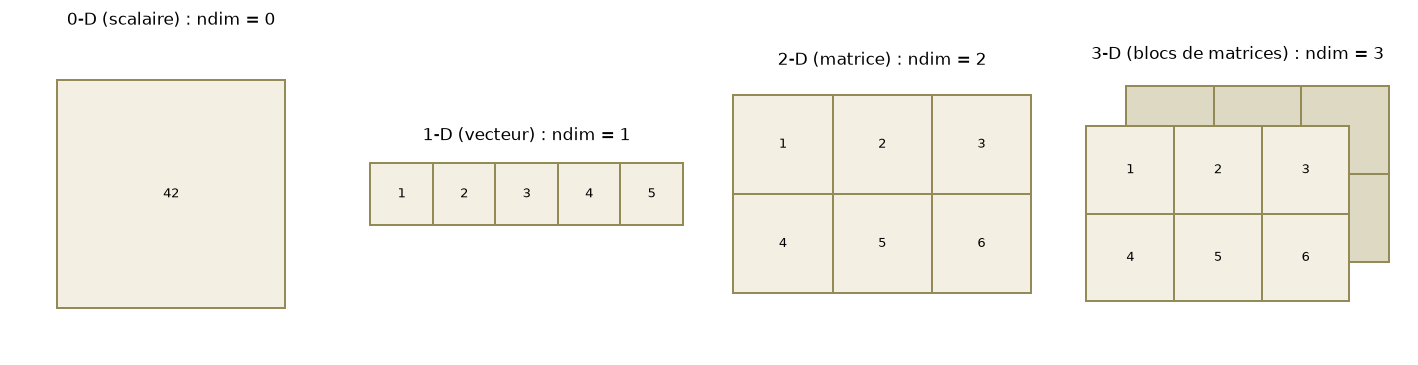

In [9]:
# Visualisation fournie : exécuter sans modifier
afficher_dimensions(a, b, c, d)

### Travail demandé

**Tâche 4.** Créez le tableau 1-D `capacites` contenant la capacité (en palettes) des zones A, B, C et D : 500, 350, 420, 280. Affichez le tableau, son type et son nombre de dimensions.

In [10]:
# A COMPLETER
capacites = np.array([500,350,420,280])
print(capacites)
print(type(capacites))
print(capacites.ndim)

[500 350 420 280]
<class 'numpy.ndarray'>
1


**Tâche 5.** Créez le tableau 2-D `stock_mini` : 2 produits (lignes) et 3 zones (colonnes), avec les valeurs 40, 15, 0 pour le premier produit et 22, 8, 31 pour le second. Affichez son nombre de dimensions.

In [ ]:
# A COMPLETER
stock_mini = np.array([[40,15,0],[22,8,31]]) #2D
print(stock_mini)
print(stock_mini.ndim)

[[40 15  0]
 [22  8 31]]
2


**Tâche 6.** Créez le tableau 3-D `planning` (nombre de camions chargés) : 2 semaines, 2 équipes par semaine, 3 jours par équipe. Semaine 1 : équipe 1 = 12, 15, 11 ; équipe 2 = 9, 14, 10. Semaine 2 : équipe 1 = 13, 16, 12 ; équipe 2 = 8, 11, 9. Affichez son nombre de dimensions.

In [ ]:
# A COMPLETER
planning = np.array([[[12,15,11],[9,14,10]],[[13,16,12],[8,11,9]]]) #3D
print(planning)
print(planning.ndim)

[[[12 15 11]
  [ 9 14 10]]

 [[13 16 12]
  [ 8 11  9]]]
3


**Tâche 7.** Affichez le nombre de dimensions des tableaux chargés depuis les CSV : `expeditions`, `stock` et `livraisons`.

In [22]:
# A COMPLETER
print(expeditions.ndim)
print(stock.ndim)
print(livraisons.ndim)

1
2
2


### Questions

**Q1.1 :** Quel est le type renvoyé par `type(capacites)` ? En quoi diffère-t-il d'une liste ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

**Q1.2 :** Pour le tableau `stock`, que représente chacune des deux dimensions ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

## PARTIE 2 : Indexation des tableaux

*Durée indicative : 25 min*

### Rappel de cours

- Indexer un tableau, c'est accéder à un élément en indiquant son numéro d'index. **Les index commencent à 0.**
- Tableau 1-D : `arr[i]`.
- Tableau 2-D : `arr[ligne, colonne]`.
- Tableau 3-D : `arr[bloc, ligne, colonne]`.
- Un index négatif compte depuis la fin : `arr[-1]` est le dernier élément.

### Exemple guidé

Cellule complète : exécutez-la et observez le résultat.

In [23]:
arr = np.array([1, 2, 3, 4])
print(arr[0])
print(arr[-1])

arr = np.array([[1, 2, 3, 4, 5], [6, 7, 8, 9, 10]])
print("2e élément de la 1re ligne :", arr[0, 1])

arr = np.array([[[1, 2, 3], [4, 5, 6]], [[7, 8, 9], [10, 11, 12]]])
print(arr[0, 1, 2])

1
4
2e élément de la 1re ligne : 2
6


### Travail demandé

**Tâche 8.** Dans `expeditions`, récupérez le volume du premier mois (`premier_mois`), du sixième mois (`sixieme_mois`) et du dernier mois avec un index négatif (`dernier_mois`).

In [24]:
# A COMPLETER
premier_mois = expeditions[0]
sixieme_mois = expeditions[5]
dernier_mois = expeditions[-1]
print(premier_mois, sixieme_mois, dernier_mois)

828 1020 1651


**Tâche 9.** Dans `stock`, récupérez dans `quantite_cible` la quantité du produit d'index 4 en zone C (colonne d'index 2). Affichez aussi le nom du produit avec `produits[4]`.

In [29]:
# A COMPLETER
quantite_cible = stock[4,2]
print(produits[4], ":", quantite_cible)

Film_etirable : 104


**Tâche 10.** Calculez dans `total_palettes_AB` la quantité totale du produit d'index 0 dans les zones A et B (addition de deux éléments indexés).

In [30]:
# A COMPLETER
total_palettes_AB = stock[0,0] + stock[0,1]
print(total_palettes_AB)

131


**Tâche 11.** Dans `planning`, récupérez dans `camions` le nombre de camions de la semaine 2, équipe 1, jour 3.

In [34]:
# A COMPLETER
camions = planning[1,0,2]
print(camions)

12


**Visualisation.** Carte du stock : la case encadrée correspond à stock[4, 2].

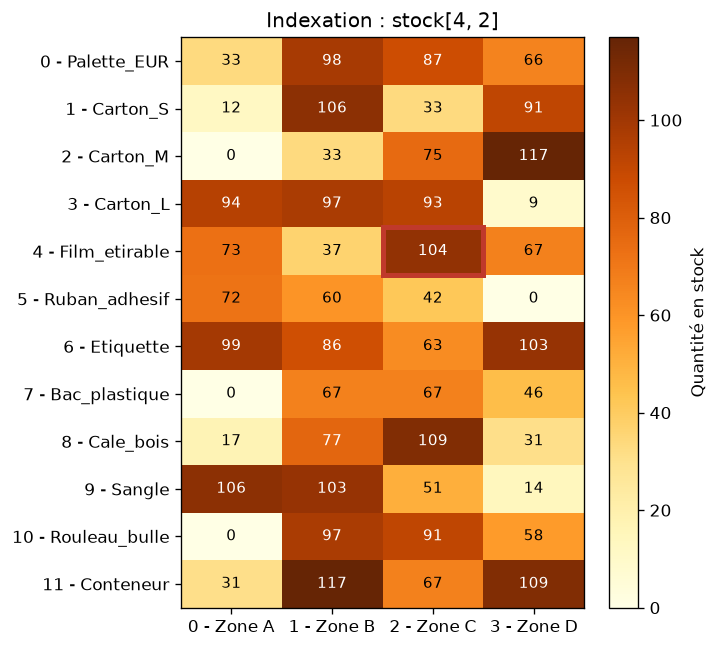

In [35]:
# Visualisation fournie : exécuter sans modifier (après avoir terminé les tâches)
afficher_stock(stock, produits, selection=(4, 5, 2, 3), titre="Indexation : stock[4, 2]")

### Questions

## PARTIE 3 : Découpage de tableaux (slicing)

*Durée indicative : 35 min*

### Rappel de cours

- Le découpage fonctionne comme pour les listes : on extrait les éléments compris entre deux index avec la notation **`[début:fin:pas]`**.
- L'index `fin` est **exclu**. Valeurs par défaut : `début` = 0, `fin` = longueur du tableau, `pas` = 1.
- Tableau 2-D : on donne une plage pour les lignes et une pour les colonnes, `arr[lignes, colonnes]`.
- Le symbole `:` seul signifie « tout » : `arr[:, 0]` renvoie toute la première colonne.

### Exemple guidé

Cellule complète : exécutez-la et observez le résultat.

In [37]:
arr = np.array([1, 2, 3, 4, 5, 6, 7])
print(arr[1:5])
print(1)
print(arr[4:])
print(2)
print(arr[::2])
print(3)

arr = np.array([[1, 2, 3, 4, 5], [6, 7, 8, 9, 10]])
print(arr[0:2, 1:4])
print(4)
print(arr[:, 0])
print(5)

[2 3 4 5]
1
[5 6 7]
2
[1 3 5 7]
3
[[2 3 4]
 [7 8 9]]
4
[1 6]
5


### Travail demandé

**Tâche 12.** Découpez `expeditions` en deux tableaux : `annee_1` (12 premiers mois) et `annee_2` (12 derniers mois). Extrayez aussi un mois sur trois dans `un_mois_sur_trois`.

In [45]:
# A COMPLETER
annee_1 = expeditions[0:12]
annee_2 = expeditions[12:]
un_mois_sur_trois = expeditions[::3]
print(annee_1)
print(annee_2)
print(un_mois_sur_trois)
print(expeditions)

[ 828  795  925  950 1026 1020  872  767 1041 1151 1345 1444]
[ 978  871 1024 1087 1129 1169  987  850 1174 1266 1503 1651]
[ 828  950  872 1151  978 1087  987 1266]
[ 828  795  925  950 1026 1020  872  767 1041 1151 1345 1444  978  871
 1024 1087 1129 1169  987  850 1174 1266 1503 1651]


**Tâche 13.** Dans `stock`, extrayez : les trois premiers produits pour toutes les zones (`trois_premiers`) ; toute la colonne de la zone B (`zone_B`) ; le bloc des produits d'index 2 à 5 dans les zones B et C (`bloc`).

In [ ]:
# A COMPLETER
trois_premiers = stock[:,0:3]
zone_B = stock[1]
bloc = stock[1:,2:6]
print(trois_premiers)
print(zone_B)
print(bloc)
#print(stock)

[[ 33  98  87]
 [ 12 106  33]
 [  0  33  75]
 [ 94  97  93]
 [ 73  37 104]
 [ 72  60  42]
 [ 99  86  63]
 [  0  67  67]
 [ 17  77 109]
 [106 103  51]
 [  0  97  91]
 [ 31 117  67]]


**Tâche 14.** Dans `livraisons`, extrayez les délais (colonne d'index 3) des 10 premières livraisons dans `delais_debut`, puis les colonnes distance et délai (index 1 et 3, à l'aide d'un pas) des 5 premières livraisons dans `distance_delai`.

In [59]:
# A COMPLETER
delais_debut = livraisons[0:10,3]
distance_delai = livraisons[0:5,1:4:2]
print(delais_debut)
print(distance_delai)
print(livraisons.ndim)


[25.3  5.2 15.7  2.   8.4 43.1 37.5 51.2 30.  33.9]
[[705.   25.3]
 [191.3   5.2]
 [430.7  15.7]
 [ 58.5   2. ]
 [155.8   8.4]]
2


**Visualisation.** Carte du stock : la zone encadrée correspond à stock[2:6, 1:3].

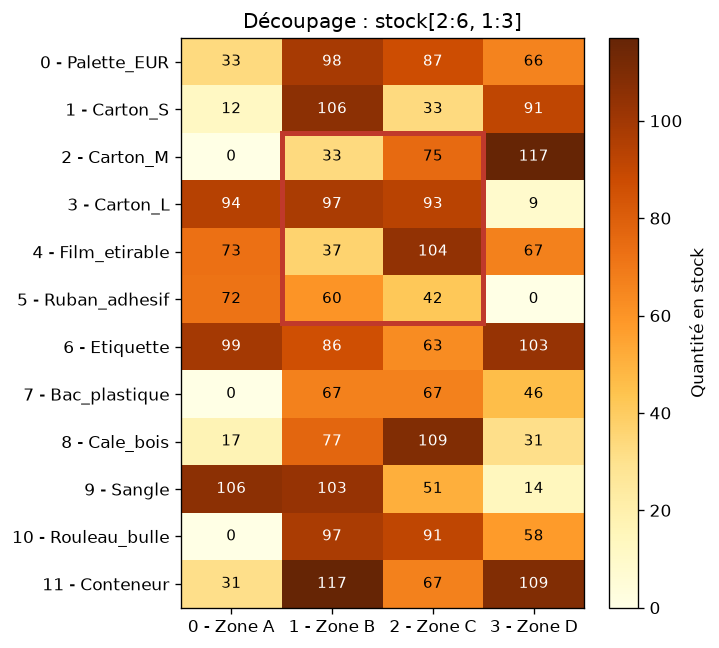

In [60]:
# Visualisation fournie : exécuter sans modifier (après avoir terminé les tâches)
afficher_stock(stock, produits, selection=(2, 6, 1, 3), titre="Découpage : stock[2:6, 1:3]")

**Visualisation.** Les deux années extraites par découpage du tableau expeditions.

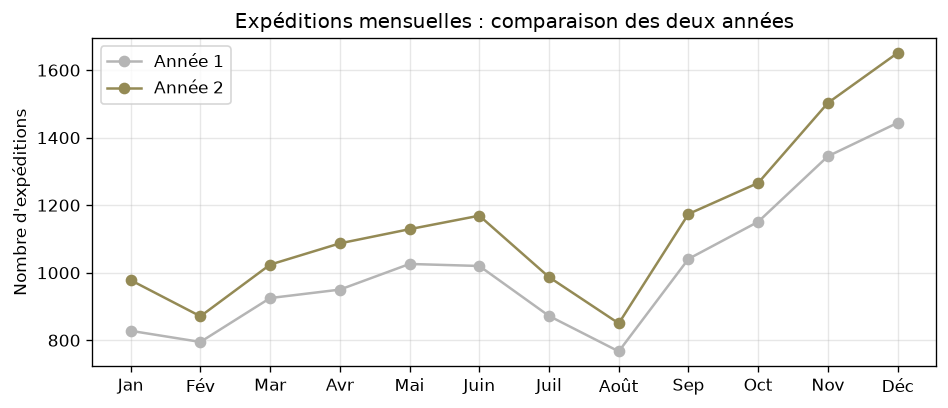

In [61]:
# Visualisation fournie : exécuter sans modifier (après avoir terminé les tâches)
afficher_expeditions(annee_1, annee_2)

### Questions

**Q3.1 :** Combien d'éléments contient `expeditions[2:10:2]` ? À quels index correspondent-ils ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

**Q3.2 :** Quelle est la différence entre `stock[1]` et `stock[:, 1]` ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

## PARTIE 4 : Redimensionnement de tableaux (reshape)

*Durée indicative : 25 min*

### Rappel de cours

- La **structure** (`shape`) d'un tableau est le nombre d'éléments dans chaque dimension. L'attribut `shape` la renvoie sous forme de tuple : `(4, 3)` signifie 4 lignes et 3 colonnes.
- Redimensionner, c'est modifier cette structure avec `reshape()` : ajouter ou supprimer des dimensions, ou changer le nombre d'éléments par dimension.
- Condition : le **nombre total d'éléments doit rester le même**. 12 éléments peuvent devenir (4, 3), (3, 4), (2, 6) ou (2, 2, 3), mais pas (5, 2).

### Exemple guidé

Cellule complète : exécutez-la et observez le résultat.

In [ ]:
arr = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
print(arr.shape)

newarr = arr.reshape(4, 3)
print(newarr)
print(newarr.shape)
print(newarr.ndim)

### Travail demandé

**Tâche 15.** Affichez la structure (`shape`) des tableaux `expeditions`, `stock` et `livraisons`.

In [ ]:
# A COMPLETER
print(...)
print(...)
print(...)

**Tâche 16.** Transformez `expeditions` (24 mois) en un tableau 2-D `expeditions_par_annee` de 2 lignes (années) et 12 colonnes (mois). Affichez sa structure et son nombre de dimensions.

In [ ]:
# A COMPLETER
expeditions_par_annee = ...
print(expeditions_par_annee)
print(...)
print(...)

**Tâche 17.** Transformez `expeditions` en un tableau 3-D `expeditions_trimestres` : 2 années, 4 trimestres par année, 3 mois par trimestre. Récupérez dans `valeur` le volume de l'année 2, trimestre 3, mois 2.

In [ ]:
# A COMPLETER
expeditions_trimestres = ...
print(expeditions_trimestres)
valeur = ...
print(valeur)

**Tâche 18.** Transformez le tableau 2-D `stock` en un tableau 1-D `stock_plat` contenant toutes les quantités. Affichez sa structure.

In [ ]:
# A COMPLETER
stock_plat = ...
print(stock_plat)
print(...)

**Visualisation.** Le tableau expeditions avant et après reshape(2, 12).

In [ ]:
# Visualisation fournie : exécuter sans modifier (après avoir terminé les tâches)
afficher_reshape(expeditions, expeditions_par_annee)

### Questions

**Q4.1 :** Peut-on écrire `expeditions.reshape(5, 5)` ? Justifiez.

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

**Q4.2 :** Citez deux autres structures possibles pour un tableau de 24 éléments.

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

## PARTIE 5 : Recherche dans les tableaux avec where()

*Durée indicative : 30 min*

### Rappel de cours

- On peut rechercher une valeur dans un tableau et obtenir les **index** où elle se trouve avec `np.where(condition)`.
- Le résultat est un **tuple** contenant un tableau d'index : `(array([3, 5, 6]),)`. Le tableau d'index s'obtient avec `resultat[0]`.
- La condition peut être une égalité (`arr == 4`) ou toute autre comparaison (`arr % 2 == 0`, `arr < 20`).
- Les index obtenus peuvent servir à récupérer les éléments correspondants : `arr[resultat]`.
- Forme complète : `np.where(condition, x, y)` renvoie un tableau de même taille contenant `x` là où la condition est vraie et `y` ailleurs.

### Exemple guidé

Cellule complète : exécutez-la et observez le résultat.

In [ ]:
# Recherche d'une valeur : où se trouve la valeur 4 ?
arr = np.array([1, 2, 3, 4, 5, 4, 4])
x = np.where(arr == 4)
print(x)

# Recherche par condition : où se trouvent les valeurs paires ?
arr = np.array([1, 2, 3, 4, 5, 6, 7, 8])
x = np.where(arr % 2 == 0)
print(x)
print(x[0])        # le tableau des index
print(arr[x])      # les valeurs situées à ces index

# Forme complète : 1 si la valeur dépasse 4, 0 sinon
etiquettes = np.where(arr > 4, 1, 0)
print(etiquettes)

### Travail demandé

**Tâche 19.** Extrayez la colonne de la zone A dans `zone_A`. Recherchez dans `indices_rupture` les index des produits en rupture (quantité égale à 0), puis récupérez leurs noms dans `produits_rupture`.

In [ ]:
# A COMPLETER
zone_A = ...
indices_rupture = ...
produits_rupture = ...
print(indices_rupture)
print(produits_rupture)

**Tâche 20.** Recherchez dans `indices_alerte` les index des produits de la zone A dont le stock est inférieur au seuil d'alerte de 20 unités. Calculez leur nombre dans `nombre_alertes` avec `len()`.

In [ ]:
# A COMPLETER
indices_alerte = ...
nombre_alertes = ...
print(indices_alerte)
print(nombre_alertes)

**Tâche 21.** Extrayez la colonne des délais (index 3) de `livraisons` dans `delai`. Une livraison est en retard si son délai dépasse 48 h : recherchez les index des livraisons en retard dans `indices_retard` et comptez-les dans `nombre_retards`.

In [ ]:
# A COMPLETER
delai = ...
indices_retard = ...
nombre_retards = ...
print(indices_retard)
print(nombre_retards)

**Tâche 22.** Avec la forme complète de `np.where`, construisez le tableau `statut_retard` qui vaut 1 pour une livraison en retard et 0 sinon. Affichez ses 20 premières valeurs.

In [ ]:
# A COMPLETER
statut_retard = ...
print(...)

**Visualisation.** Stock de la zone A : produits sous le seuil d'alerte repérés par np.where().

In [ ]:
# Visualisation fournie : exécuter sans modifier (après avoir terminé les tâches)
afficher_alertes(zone_A, produits, indices_alerte, seuil=20)

### Questions

**Q5.1 :** Pourquoi faut-il écrire `indices_alerte[0]` pour compter les produits en alerte ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

**Q5.2 :** Quelle est la différence entre `np.where(delai > 48)` et `np.where(delai > 48, 1, 0)` ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

## PARTIE 6 : Filtrage par tableau de booléens

*Durée indicative : 30 min*

### Rappel de cours

- **Filtrer**, c'est extraire certains éléments d'un tableau existant pour en créer un nouveau.
- Dans NumPy, on filtre un tableau à l'aide d'une liste (ou d'un tableau) de **booléens** de même longueur.
- Si la valeur à un index donné est `True`, l'élément est inclus dans le tableau filtré ; si elle est `False`, il est exclu.
- En pratique, le filtre est créé directement par une condition : `filtre = arr > 42` renvoie un tableau de booléens, que l'on applique avec `arr[filtre]`.

### Exemple guidé

Cellule complète : exécutez-la et observez le résultat.

In [ ]:
arr = np.array([41, 42, 43, 44])

# Filtre écrit à la main
x = [True, False, True, False]
newarr = arr[x]
print(newarr)

# Filtre créé par une condition
filtre = arr > 42
print(filtre)
print(arr[filtre])

### Travail demandé

**Tâche 23.** Écrivez à la main le filtre `filtre_manuel` (liste de 4 booléens) qui conserve uniquement les zones A et C dans `capacites`. Appliquez-le pour obtenir `capacites_AC`.

In [ ]:
# A COMPLETER
filtre_manuel = ...
capacites_AC = ...
print(capacites_AC)

**Tâche 24.** Extrayez la colonne des distances (index 1) dans `distance`. Créez le filtre `filtre_retard` (délai supérieur à 48 h) puis obtenez `delais_en_retard` et `distances_en_retard`. Affichez le nombre de livraisons en retard.

In [ ]:
# A COMPLETER
distance = ...
filtre_retard = ...
delais_en_retard = ...
distances_en_retard = ...
print(len(delais_en_retard))
print(distances_en_retard)

**Tâche 25.** Extrayez les colonnes poids (index 2) et coût (index 4) dans `poids` et `cout`. Filtrez les coûts des livraisons lourdes (poids supérieur à 800 kg) dans `couts_lourds`. Comparez le coût moyen des livraisons lourdes au coût moyen général (la méthode `.mean()` renvoie la moyenne d'un tableau).

In [ ]:
# A COMPLETER
poids = ...
cout = ...
filtre_lourd = ...
couts_lourds = ...
print("Coût moyen général :", round(cout.mean(), 2))
print("Coût moyen des livraisons lourdes :", round(couts_lourds.mean(), 2))

**Visualisation.** Livraisons en retard isolées par le filtre booléen.

In [ ]:
# Visualisation fournie : exécuter sans modifier (après avoir terminé les tâches)
afficher_livraisons(distance, delai, filtre_retard)

### Questions

**Q6.1 :** Quelle est la différence entre le résultat de `np.where(delai > 48)` et celui de `delai[delai > 48]` ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

**Q6.2 :** D'après le graphique, quelles livraisons sont le plus souvent en retard ?

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

## PARTIE 7 : Synthèse : audit de l'entrepôt LogiStock

*Durée indicative : 25 min*

Ces deux exercices, de difficulté moyenne, combinent toutes les notions du TP. Aucun exemple guidé n'est fourni : à vous de choisir les bons outils.

### Travail demandé

**Tâche 26.** **Audit de la zone D.** Extrayez la colonne de la zone D dans `zone_D`. Construisez le filtre `filtre_alerte_D` (stock inférieur à 20), puis obtenez les noms des produits concernés (`produits_alerte_D`) et leurs quantités (`quantites_alerte_D`). Recherchez enfin avec `np.where` l'index du ou des produits en rupture totale (`indices_rupture_D`).

In [ ]:
# A COMPLETER
zone_D = ...
filtre_alerte_D = ...
produits_alerte_D = ...
quantites_alerte_D = ...
indices_rupture_D = ...
print(produits_alerte_D)
print(quantites_alerte_D)
print(indices_rupture_D)

**Tâche 27.** **Analyse des tournées.** Les 200 livraisons sont réparties en 20 tournées de 10 livraisons. Redimensionnez `delai` en `delai_tournees` (20 lignes, 10 colonnes). Extrayez la tournée d'index 4 (`tournee_4`), puis ses délais en retard (`retards_tournee_4`). Extrayez les 5 premières livraisons des 3 premières tournées (`debut_tournees`). Construisez enfin `statut_tournees`, qui vaut 1 pour un retard et 0 sinon.

In [ ]:
# A COMPLETER
delai_tournees = ...
tournee_4 = ...
retards_tournee_4 = ...
debut_tournees = ...
statut_tournees = ...
print(delai_tournees.shape)
print(tournee_4)
print(retards_tournee_4)
print(debut_tournees)
print(statut_tournees)

**Visualisation.** Tableau de bord LogiStock construit à partir de vos tableaux.

In [ ]:
# Visualisation fournie : exécuter sans modifier (après avoir terminé les tâches)
afficher_tableau_de_bord(stock, expeditions_par_annee, distance, delai, filtre_retard, statut_tournees)

### Questions

**Q7.1 :** En observant le tableau de bord, formulez trois constats utiles au responsable de l'entrepôt.

**Réponse :** *(double-cliquez pour rédiger votre réponse)*

## Fin du TP

Enregistrez votre notebook complété (`Fichier > Télécharger > .ipynb`) et déposez-le selon les consignes de l'enseignant.